In [2]:
import pandas as pd
from pathlib import Path

project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

data_path = project_path / "data" / "processed"

train_df = pd.read_csv(data_path / "train.csv")
val_df = pd.read_csv(data_path / "validation.csv")

X_train = train_df["text"]
y_train = train_df["label"]

X_val = val_df["text"]
y_val = val_df["label"]

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Disease classes:", y_train.nunique())

Training: 803
Validation: 178
Disease classes: 24


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

model_lr = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

model_lr.fit(X_train, y_train)

predictions = model_lr.predict(X_val)

print("Logistic Regression Results")
print("Accuracy:", round(
    accuracy_score(y_val, predictions), 4
))
print("Macro F1:", round(
    f1_score(y_val, predictions, average="macro"), 4
))

Logistic Regression Results
Accuracy: 0.9551
Macro F1: 0.9557


In [4]:
from sklearn.metrics import classification_report, confusion_matrix

print("Logistic Regression - Classification Report")

print(
    classification_report(
        y_val,
        predictions,
        digits=4,
        zero_division=0
    )
)

Logistic Regression - Classification Report
                                 precision    recall  f1-score   support

                           Acne     1.0000    1.0000    1.0000         5
                      Arthritis     1.0000    1.0000    1.0000         8
               Bronchial Asthma     1.0000    1.0000    1.0000         7
           Cervical spondylosis     1.0000    1.0000    1.0000         8
                    Chicken pox     1.0000    0.7500    0.8571         8
                    Common Cold     0.9091    1.0000    0.9524        10
                         Dengue     0.8889    1.0000    0.9412         8
          Dimorphic Hemorrhoids     1.0000    1.0000    1.0000         7
               Fungal infection     1.0000    1.0000    1.0000         6
                   Hypertension     0.8750    1.0000    0.9333         7
                       Impetigo     1.0000    1.0000    1.0000         7
                       Jaundice     1.0000    1.0000    1.0000         6
      

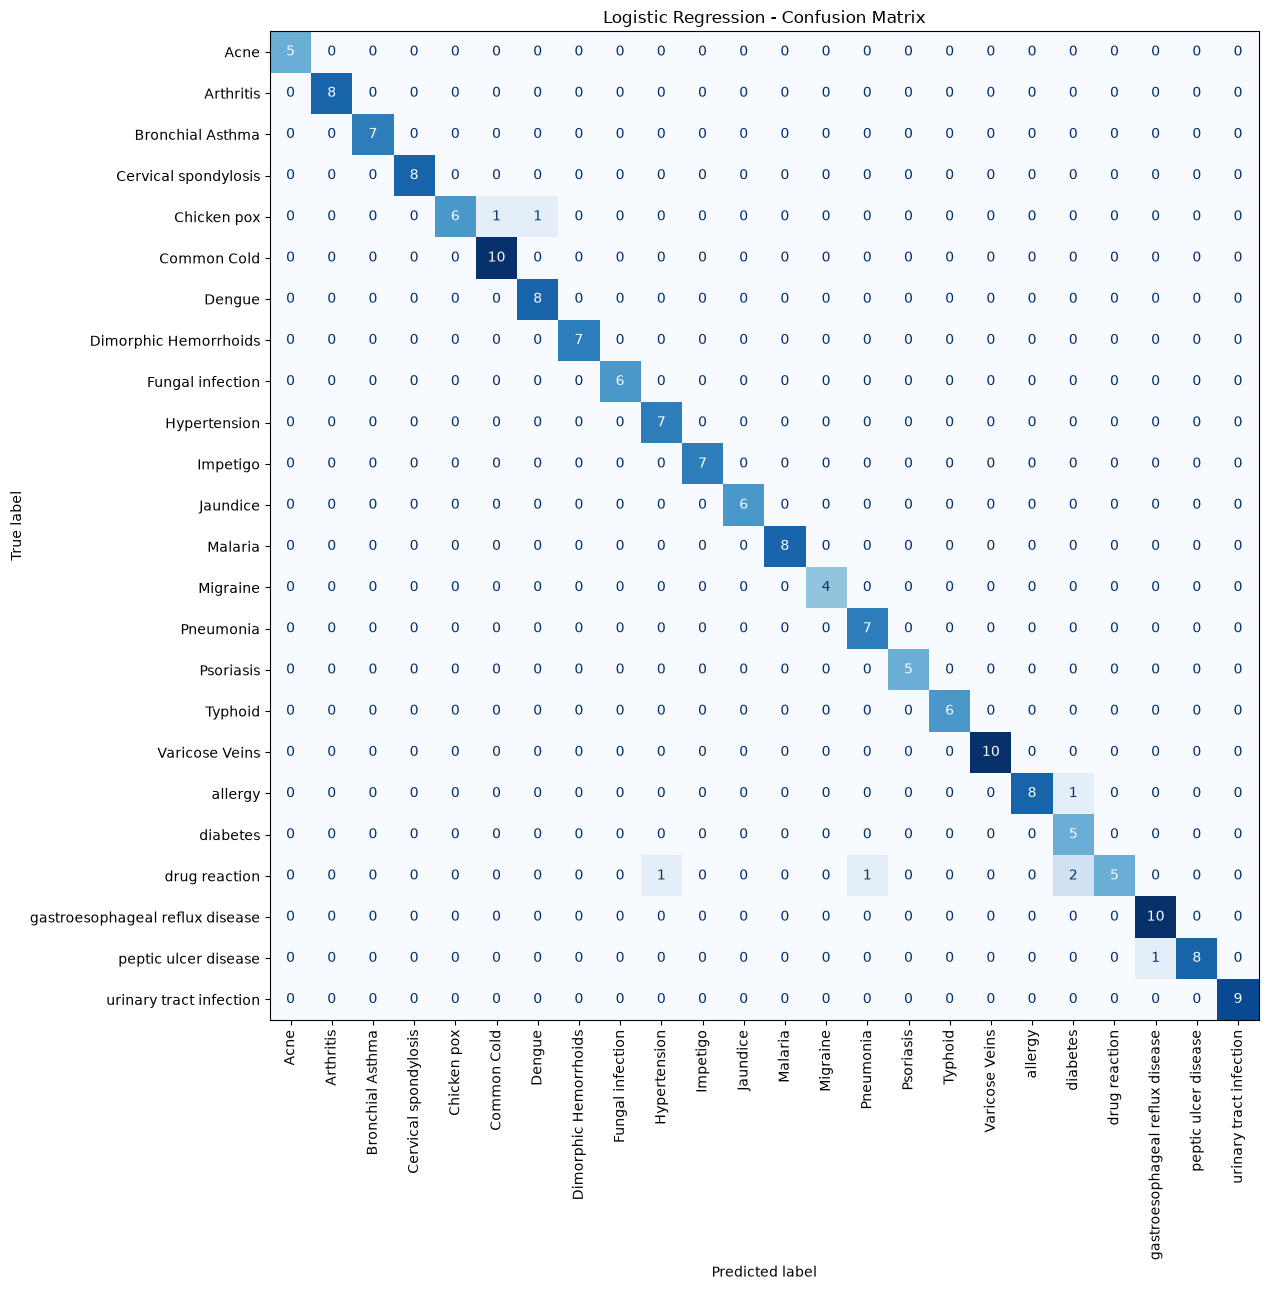

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(15, 13))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    predictions,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=False
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score

model_svm = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2)
    )),
    ("classifier", LinearSVC(
        random_state=42
    ))
])

model_svm.fit(X_train, y_train)

predictions_svm = model_svm.predict(X_val)

print("SVM Results")
print("Accuracy:", round(
    accuracy_score(y_val, predictions_svm), 4
))
print("Macro F1:", round(
    f1_score(y_val, predictions_svm, average="macro"), 4
))

SVM Results
Accuracy: 0.9775
Macro F1: 0.9793


In [7]:
from sklearn.metrics import classification_report

print("SVM - Classification Report")

print(
    classification_report(
        y_val,
        predictions_svm,
        digits=4,
        zero_division=0
    )
)

SVM - Classification Report
                                 precision    recall  f1-score   support

                           Acne     1.0000    1.0000    1.0000         5
                      Arthritis     1.0000    1.0000    1.0000         8
               Bronchial Asthma     1.0000    1.0000    1.0000         7
           Cervical spondylosis     1.0000    1.0000    1.0000         8
                    Chicken pox     1.0000    0.8750    0.9333         8
                    Common Cold     0.9091    1.0000    0.9524        10
                         Dengue     1.0000    1.0000    1.0000         8
          Dimorphic Hemorrhoids     1.0000    1.0000    1.0000         7
               Fungal infection     1.0000    1.0000    1.0000         6
                   Hypertension     0.8750    1.0000    0.9333         7
                       Impetigo     1.0000    1.0000    1.0000         7
                       Jaundice     1.0000    1.0000    1.0000         6
                      

In [8]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions, average="macro"
        )
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_score(y_val, predictions_svm),
        "Macro F1": f1_score(
            y_val, predictions_svm, average="macro"
        )
    }
])

display(results.round(4))

,Model,Accuracy,Macro F1
0,Logistic Regression,0.9551,0.9557
1,SVM,0.9775,0.9793


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score

model_knn = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2)
    )),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine"
    ))
])

model_knn.fit(X_train, y_train)

predictions_knn = model_knn.predict(X_val)

print("KNN Results")
print("Accuracy:", round(
    accuracy_score(y_val, predictions_knn), 4
))
print("Macro F1:", round(
    f1_score(y_val, predictions_knn, average="macro"), 4
))

KNN Results
Accuracy: 0.9045
Macro F1: 0.9078


In [10]:
from sklearn.metrics import classification_report

print("KNN - Classification Report")

print(
    classification_report(
        y_val,
        predictions_knn,
        digits=4,
        zero_division=0
    )
)

KNN - Classification Report
                                 precision    recall  f1-score   support

                           Acne     1.0000    1.0000    1.0000         5
                      Arthritis     0.8000    1.0000    0.8889         8
               Bronchial Asthma     0.7778    1.0000    0.8750         7
           Cervical spondylosis     0.8889    1.0000    0.9412         8
                    Chicken pox     0.7273    1.0000    0.8421         8
                    Common Cold     1.0000    1.0000    1.0000        10
                         Dengue     1.0000    0.8750    0.9333         8
          Dimorphic Hemorrhoids     1.0000    1.0000    1.0000         7
               Fungal infection     1.0000    1.0000    1.0000         6
                   Hypertension     1.0000    1.0000    1.0000         7
                       Impetigo     0.8750    1.0000    0.9333         7
                       Jaundice     1.0000    1.0000    1.0000         6
                      

In [11]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro")
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_score(y_val, predictions_svm),
        "Macro F1": f1_score(y_val, predictions_svm, average="macro")
    },
    {
        "Model": "KNN",
        "Accuracy": accuracy_score(y_val, predictions_knn),
        "Macro F1": f1_score(y_val, predictions_knn, average="macro")
    }
])

display(results.round(4))

,Model,Accuracy,Macro F1
0,Logistic Regression,0.9551,0.9557
1,SVM,0.9775,0.9793
2,KNN,0.9045,0.9078


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score

model_rf = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2)
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

model_rf.fit(X_train, y_train)

predictions_rf = model_rf.predict(X_val)

print("Random Forest Results")
print("Accuracy:", round(
    accuracy_score(y_val, predictions_rf), 4
))
print("Macro F1:", round(
    f1_score(y_val, predictions_rf, average="macro"), 4
))

Random Forest Results
Accuracy: 0.9382
Macro F1: 0.9386


In [14]:
from sklearn.metrics import classification_report

print("Random Forest - Classification Report")

print(
    classification_report(
        y_val,
        predictions_rf,
        digits=4,
        zero_division=0
    )
)

Random Forest - Classification Report
                                 precision    recall  f1-score   support

                           Acne     1.0000    1.0000    1.0000         5
                      Arthritis     0.8889    1.0000    0.9412         8
               Bronchial Asthma     1.0000    1.0000    1.0000         7
           Cervical spondylosis     1.0000    1.0000    1.0000         8
                    Chicken pox     1.0000    0.8750    0.9333         8
                    Common Cold     1.0000    1.0000    1.0000        10
                         Dengue     0.7778    0.8750    0.8235         8
          Dimorphic Hemorrhoids     1.0000    1.0000    1.0000         7
               Fungal infection     0.8571    1.0000    0.9231         6
                   Hypertension     0.8750    1.0000    0.9333         7
                       Impetigo     1.0000    1.0000    1.0000         7
                       Jaundice     1.0000    1.0000    1.0000         6
            

In [13]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro")
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_score(y_val, predictions_svm),
        "Macro F1": f1_score(y_val, predictions_svm, average="macro")
    },
    {
        "Model": "KNN",
        "Accuracy": accuracy_score(y_val, predictions_knn),
        "Macro F1": f1_score(y_val, predictions_knn, average="macro")
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_val, predictions_rf),
        "Macro F1": f1_score(y_val, predictions_rf, average="macro")
    }
])

results = results.sort_values(
    "Macro F1", ascending=False
)

display(results.round(4))

,Model,Accuracy,Macro F1
1,SVM,0.9775,0.9793
0,Logistic Regression,0.9551,0.9557
3,Random Forest,0.9382,0.9386
2,KNN,0.9045,0.9078


Neural Network

In [15]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score

model_mlp = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2)
    )),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64,),
        activation="relu",
        solver="adam",
        max_iter=300,
        random_state=42
    ))
])

model_mlp.fit(X_train, y_train)

predictions_mlp = model_mlp.predict(X_val)

print("Neural Network (MLP) Results")
print("Accuracy:", round(
    accuracy_score(y_val, predictions_mlp), 4
))
print("Macro F1:", round(
    f1_score(y_val, predictions_mlp, average="macro"), 4
))

print("Training iterations:",
      model_mlp.named_steps["classifier"].n_iter_)

Neural Network (MLP) Results
Accuracy: 0.9551
Macro F1: 0.9593
Training iterations: 177


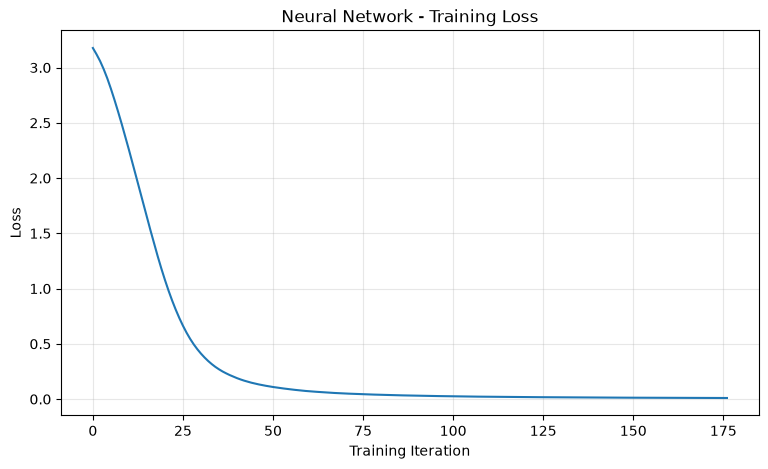

Final training loss: 0.0101


In [16]:
import matplotlib.pyplot as plt

mlp = model_mlp.named_steps["classifier"]

plt.figure(figsize=(9, 5))

plt.plot(mlp.loss_curve_)

plt.title("Neural Network - Training Loss")
plt.xlabel("Training Iteration")
plt.ylabel("Loss")
plt.grid(alpha=0.3)
plt.show()

print("Final training loss:", round(mlp.loss_, 4))

In [17]:
from sklearn.metrics import classification_report

print("MLP - Classification Report")

print(classification_report(
    y_val,
    predictions_mlp,
    digits=4,
    zero_division=0
))

MLP - Classification Report
                                 precision    recall  f1-score   support

                           Acne     1.0000    1.0000    1.0000         5
                      Arthritis     1.0000    1.0000    1.0000         8
               Bronchial Asthma     1.0000    1.0000    1.0000         7
           Cervical spondylosis     1.0000    1.0000    1.0000         8
                    Chicken pox     0.8750    0.8750    0.8750         8
                    Common Cold     0.9091    1.0000    0.9524        10
                         Dengue     1.0000    1.0000    1.0000         8
          Dimorphic Hemorrhoids     1.0000    1.0000    1.0000         7
               Fungal infection     1.0000    1.0000    1.0000         6
                   Hypertension     1.0000    1.0000    1.0000         7
                       Impetigo     1.0000    1.0000    1.0000         7
                       Jaundice     1.0000    1.0000    1.0000         6
                      

In [18]:
model_predictions = {
    "Logistic Regression": predictions,
    "SVM": predictions_svm,
    "KNN": predictions_knn,
    "Random Forest": predictions_rf,
    "Neural Network (MLP)": predictions_mlp
}

results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Macro F1": f1_score(
            y_val, pred, average="macro"
        )
    }
    for name, pred in model_predictions.items()
])

results = results.sort_values(
    by="Macro F1",
    ascending=False
)

display(results.round(4))

,Model,Accuracy,Macro F1
1,SVM,0.9775,0.9793
4,Neural Network (MLP),0.9551,0.9593
0,Logistic Regression,0.9551,0.9557
3,Random Forest,0.9382,0.9386
2,KNN,0.9045,0.9078


In [19]:
from pathlib import Path

results_path = project_path / "models"
results_path.mkdir(parents=True, exist_ok=True)

results.to_csv(
    results_path / "baseline_results.csv",
    index=False
)

print("Baseline results saved successfully!")
display(results.round(4))

Baseline results saved successfully!


,Model,Accuracy,Macro F1
1,SVM,0.9775,0.9793
4,Neural Network (MLP),0.9551,0.9593
0,Logistic Regression,0.9551,0.9557
3,Random Forest,0.9382,0.9386
2,KNN,0.9045,0.9078
